# 1. IMPORTS AND CONFIGURATION

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import yfinance as yf
from datetime import datetime, timedelta
import logging
import matplotlib.pyplot as plt

# Configurar logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')


# 2. CONFIGURACIÓN – AJUSTA SEGÚN TU ENTORNO

In [2]:
# Conexión MongoDB
MONGO_URI = os.getenv("MONGODB_URI_FUTURES_3", "mongodb+srv://...")  # Reemplaza con tu URI o defínela en .env
MONGO_DB = os.getenv("MONGODB_DB", "market_data")
COLLECTION_NAME = "es_15min"  # Colección de origen

# Nombres de archivos de salida
CSV_15MIN = "es_15min_full.csv"
CSV_1H = "es_1h_full.csv"
CSV_4H = "es_4h_full.csv"
CSV_1D = "es_1d.csv"  # (del resampleo original)

VALIDATION_REPORT_1H = "es_1h_validation_report.txt"
VALIDATION_REPORT_4H = "es_4h_validation_report.txt"

# Símbolo de Yahoo
YAHOO_SYMBOL = "ES=F"

# Rango para validación intradía directa (últimos 60 días, ya que Yahoo limita los datos de 1h a ~60 días)
INTRADAY_DAYS = 60

# 3. CONEXIÓN A MONGODB Y CARGA DE DATOS BASE (15min)

In [3]:
from pymongo import MongoClient
from pymongo.errors import ConnectionFailure, ServerSelectionTimeoutError

def get_mongo_client(uri):
    """Create MongoDB client with error handling."""
    if not uri:
        raise ValueError("MongoDB URI is required.")
    client = MongoClient(
        uri,
        serverSelectionTimeoutMS=5000,
        connectTimeoutMS=3000,
        socketTimeoutMS=30000,
        maxPoolSize=50,
        minPoolSize=5,
        retryWrites=True,
        w="majority"
    )
    try:
        client.admin.command("ping")
        logging.info("✅ MongoDB connection successful.")
    except (ConnectionFailure, ServerSelectionTimeoutError) as e:
        logging.error(f"❌ MongoDB connection failed: {e}")
        raise ConnectionError(f"Cannot connect to MongoDB: {e}")
    return client

# Conectar
client = get_mongo_client(MONGO_URI)
db = client[MONGO_DB]
collection = db[COLLECTION_NAME]

# Cargar todos los datos de 15 minutos
logging.info(f"Cargando datos desde '{COLLECTION_NAME}'...")
cursor = collection.find({}, {'_id': 0, 'timestamp': 1, 'open': 1, 'high': 1, 'low': 1, 'close': 1, 'volume': 1})
df_raw = pd.DataFrame(list(cursor))

if df_raw.empty:
    logging.error("❌ No se encontraron datos en la colección.")
    sys.exit(1)

# Limpiar y ordenar
df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp']).dt.tz_localize(None)
df_raw = df_raw.sort_values('timestamp').reset_index(drop=True)

# 👇 CRUCIAL: Convertir a UTC para alinear con Yahoo
# Si tus datos están en America/Chicago o America/Bogota, descomenta la línea adecuada
# df_raw['timestamp'] = df_raw['timestamp'].dt.tz_localize('America/Chicago').dt.tz_convert('UTC')
# df_raw['timestamp'] = df_raw['timestamp'].dt.tz_localize('America/Bogota').dt.tz_convert('UTC')
# Si ya están en UTC, solo asegúrate de que sean naive (sin zona horaria):
df_raw['timestamp'] = df_raw['timestamp'].dt.tz_localize(None)

logging.info(f"✅ Cargados {len(df_raw):,} registros de 15 minutos.")
logging.info(f"   Rango: {df_raw['timestamp'].min()} -> {df_raw['timestamp'].max()}")

2026-08-15 21:51:10,388 - INFO - ✅ MongoDB connection successful.
2026-08-15 21:51:10,389 - INFO - Cargando datos desde 'es_15min'...
2026-08-15 21:51:16,457 - INFO - ✅ Cargados 397,203 registros de 15 minutos.
2026-08-15 21:51:16,459 - INFO -    Rango: 2009-09-27 18:00:00 -> 2026-08-14 16:45:00


# 4. RESAMPLEO A 1H, 4H Y 1D

In [4]:
logging.info("Resampleando a velas de 1 hora...")
df_1h = df_raw.resample('1h', on='timestamp').agg({   # 'H' -> 'h'
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna().reset_index()
df_1h['timestamp'] = df_1h['timestamp'].dt.tz_localize(None)
logging.info(f"✅ Velas de 1 hora: {len(df_1h):,} registros.")
logging.info(f"   Rango: {df_1h['timestamp'].min()} -> {df_1h['timestamp'].max()}")

logging.info("Resampleando a velas de 4 horas...")
df_4h = df_raw.resample('4h', on='timestamp').agg({   # 'H' -> 'h'
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna().reset_index()
df_4h['timestamp'] = df_4h['timestamp'].dt.tz_localize(None)
logging.info(f"✅ Velas de 4 horas: {len(df_4h):,} registros.")
logging.info(f"   Rango: {df_4h['timestamp'].min()} -> {df_4h['timestamp'].max()}")

logging.info("Resampleando a velas diarias (1D)...")
df_daily = df_raw.resample('D', on='timestamp').agg({  # 'D' está bien (mayúscula para día)
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna().reset_index()
df_daily['timestamp'] = df_daily['timestamp'].dt.tz_localize(None)
logging.info(f"✅ Velas diarias: {len(df_daily):,} registros.")
logging.info(f"   Rango: {df_daily['timestamp'].min()} -> {df_daily['timestamp'].max()}")

2026-08-15 21:51:16,470 - INFO - Resampleando a velas de 1 hora...
2026-08-15 21:51:16,510 - INFO - ✅ Velas de 1 hora: 101,021 registros.
2026-08-15 21:51:16,510 - INFO -    Rango: 2009-09-27 18:00:00 -> 2026-08-14 16:00:00
2026-08-15 21:51:16,511 - INFO - Resampleando a velas de 4 horas...
2026-08-15 21:51:16,523 - INFO - ✅ Velas de 4 horas: 26,970 registros.
2026-08-15 21:51:16,523 - INFO -    Rango: 2009-09-27 16:00:00 -> 2026-08-14 16:00:00
2026-08-15 21:51:16,524 - INFO - Resampleando a velas diarias (1D)...
2026-08-15 21:51:16,534 - INFO - ✅ Velas diarias: 5,252 registros.
2026-08-15 21:51:16,535 - INFO -    Rango: 2009-09-27 00:00:00 -> 2026-08-14 00:00:00


# 5. GUARDAR A CSV


In [5]:
df_raw.to_csv(CSV_15MIN, index=False)
logging.info(f"✅ Datos de 15 minutos guardados en '{CSV_15MIN}' ({len(df_raw):,} filas).")

df_1h.to_csv(CSV_1H, index=False)
logging.info(f"✅ Datos de 1 hora guardados en '{CSV_1H}' ({len(df_1h):,} filas).")

df_4h.to_csv(CSV_4H, index=False)
logging.info(f"✅ Datos de 4 horas guardados en '{CSV_4H}' ({len(df_4h):,} filas).")

df_daily.to_csv(CSV_1D, index=False)
logging.info(f"✅ Datos diarios guardados en '{CSV_1D}' ({len(df_daily):,} filas).")

2026-08-15 21:51:17,449 - INFO - ✅ Datos de 15 minutos guardados en 'es_15min_full.csv' (397,203 filas).
2026-08-15 21:51:17,675 - INFO - ✅ Datos de 1 hora guardados en 'es_1h_full.csv' (101,021 filas).
2026-08-15 21:51:17,736 - INFO - ✅ Datos de 4 horas guardados en 'es_4h_full.csv' (26,970 filas).
2026-08-15 21:51:17,750 - INFO - ✅ Datos diarios guardados en 'es_1d.csv' (5,252 filas).


# 6. FUNCIÓN DE VALIDACIÓN CONTRA YAHOO FINANCE (DIARIA + INTRADÍA)


In [6]:
def validate_against_yahoo(df_resampled, label, report_filename, yahoo_symbol="NQ=F", intraday_days=60):
    """
    Valida un DataFrame resampleado (1H o 4H) comparando:
      1. Cierre diario agregado vs Yahoo diario.
      2. Precios intradía directos vs Yahoo 1H (últimos `intraday_days` días).
    """
    logging.info(f"🔄 Validando datos de {label}...")

    # --- 1. VALIDACIÓN DIARIA (agregada) ---
    df_daily = df_resampled.resample('D', on='timestamp').agg({'close': 'last'}).dropna()
    df_daily.index = df_daily.index.tz_localize(None)

    start_date = df_daily.index.min().date()
    end_date = df_daily.index.max().date()

    logging.info(f"Descargando referencia diaria de Yahoo ({yahoo_symbol})...")
    df_yahoo = yf.download(yahoo_symbol, start=start_date, end=end_date, interval='1d', progress=False)

    if df_yahoo.empty:
        logging.warning("⚠️ Yahoo no devolvió datos diarios. Intentando con QQQ...")
        df_yahoo = yf.download("QQQ", start=start_date, end=end_date, interval='1d', progress=False)

    if df_yahoo.empty:
        logging.error("❌ No se pudo obtener referencia diaria. Validación omitida.")
        return False

    df_yahoo.index = pd.to_datetime(df_yahoo.index).tz_localize(None)
    yahoo_close = df_yahoo['Close']

    common_dates = pd.Index(df_daily.index).intersection(yahoo_close.index).sort_values()

    if len(common_dates) < 3:
        logging.warning("⚠️ Pocas fechas comunes para validación diaria.")
        return False

    our_prices = np.ravel(df_daily.reindex(common_dates)['close'].values)
    ref_prices = np.ravel(yahoo_close.reindex(common_dates).values)

    mask = ~(np.isnan(our_prices) | np.isnan(ref_prices))
    our_prices, ref_prices = our_prices[mask], ref_prices[mask]

    if len(our_prices) < 3:
        logging.warning("⚠️ Pocos puntos válidos después de limpiar NaN.")
        return False

    corr = np.corrcoef(our_prices, ref_prices)[0, 1]
    mae = np.mean(np.abs(our_prices - ref_prices))
    max_diff = np.max(np.abs(our_prices - ref_prices))

    print(f"\n📊 VALIDACIÓN DIARIA - {label}")
    print("="*60)
    print(f"Correlación:         {corr:.6f}")
    print(f"Error absoluto medio: {mae:.4f} puntos")
    print(f"Diferencia máxima:   {max_diff:.4f} puntos")
    print("="*60)

    diaria_passed = corr > 0.99
    status = "✅ PASÓ" if diaria_passed else "⚠️ ADVERTENCIA – Correlación < 0.99"
    print(f"Estado: {status}")

    # Gráfico diario
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(df_daily.index, df_daily['close'], label=f'{label} (Agregado a diario)', linewidth=1.5, color='blue')
    ax.plot(yahoo_close.index, yahoo_close, label=f'Yahoo Finance ({yahoo_symbol})', linewidth=1.5, color='red', alpha=0.7, linestyle='--')
    ax.set_title(f'{label} vs Yahoo Diario\nCorrelación: {corr:.6f}')
    ax.set_xlabel('Fecha')
    ax.set_ylabel('Precio')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # --- 2. VALIDACIÓN INTRADÍA DIRECTA (últimos `intraday_days` días) ---
    logging.info(f"🔄 Validación intradía directa para {label} (últimos {intraday_days} días)...")
    end_intra = datetime.now()
    start_intra = end_intra - timedelta(days=intraday_days)

    df_recent = df_resampled[(df_resampled['timestamp'] >= start_intra) & (df_resampled['timestamp'] <= end_intra)]
    if df_recent.empty:
        logging.warning("⚠️ No hay datos recientes para validación intradía.")
    else:
        # Yahoo solo da 1h, así que lo usamos como base
        logging.info(f"Descargando datos intradía 1H de Yahoo ({yahoo_symbol})...")
        df_yahoo_intra = yf.download(yahoo_symbol, start=start_intra, end=end_intra, interval="1h", progress=False)

        if not df_yahoo_intra.empty:
            df_yahoo_intra.index = pd.to_datetime(df_yahoo_intra.index).tz_localize(None)

            # Si estamos validando 4H, resampleamos Yahoo 1H a 4H
            if label == "4H":
                logging.info("   Resampleando Yahoo 1H -> 4H...")
                df_yahoo_intra = df_yahoo_intra.resample('4H').agg({
                    'Open': 'first',
                    'High': 'max',
                    'Low': 'min',
                    'Close': 'last',
                    'Volume': 'sum'
                }).dropna()

            # Alinear timestamps exactos
            common_ts = pd.Index(df_recent['timestamp']).intersection(df_yahoo_intra.index).sort_values()

            if len(common_ts) > 5:
                our_intra = np.ravel(df_recent.set_index('timestamp').reindex(common_ts)['close'].values)
                ref_intra = np.ravel(df_yahoo_intra.reindex(common_ts)['Close'].values)

                mask = ~(np.isnan(our_intra) | np.isnan(ref_intra))
                our_intra, ref_intra = our_intra[mask], ref_intra[mask]

                if len(our_intra) > 5:
                    corr_intra = np.corrcoef(our_intra, ref_intra)[0, 1]
                    mae_intra = np.mean(np.abs(our_intra - ref_intra))
                    max_diff_intra = np.max(np.abs(our_intra - ref_intra))

                    print(f"\n📊 VALIDACIÓN INTRADÍA - {label} (últimos {intraday_days} días)")
                    print("="*60)
                    print(f"Correlación intradía: {corr_intra:.6f}")
                    print(f"Error absoluto medio: {mae_intra:.4f} puntos")
                    print(f"Diferencia máxima:   {max_diff_intra:.4f} puntos")
                    print("="*60)
                    intra_passed = corr_intra > 0.99
                    print(f"Estado: {'✅ PASÓ' if intra_passed else '⚠️ ADVERTENCIA'}")
                else:
                    logging.warning("⚠️ Pocos puntos comunes para validación intradía después de limpiar NaN.")
            else:
                logging.warning("⚠️ No hay suficientes timestamps comunes para validación intradía.")
        else:
            logging.warning("⚠️ Yahoo no devolvió datos intradía.")

    # Guardar reporte
    with open(report_filename, 'w') as f:
        f.write(f"{label} Data Validation Report\n")
        f.write(f"{'='*60}\n")
        f.write(f"Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write(f"Data period: {start_date} -> {end_date}\n")
        f.write(f"Total {label} candles: {len(df_resampled)}\n")
        f.write(f"Common dates with Yahoo (daily): {len(common_dates)}\n")
        f.write(f"Correlation (daily): {corr:.6f}\n")
        f.write(f"Mean Absolute Error: {mae:.4f}\n")
        f.write(f"Maximum Difference: {max_diff:.4f}\n")
        f.write(f"Status: {status}\n")
    logging.info(f"✅ Reporte guardado en '{report_filename}'.")

    return diaria_passed

# 7. VALIDACIÓN – VELAS DE 1 HORA

2026-08-15 21:51:17,769 - INFO - 🔄 Validando datos de 1H...
2026-08-15 21:51:17,774 - INFO - Descargando referencia diaria de Yahoo (ES=F)...



📊 VALIDACIÓN DIARIA - 1H
Correlación:         0.999963
Error absoluto medio: 7.2775 puntos
Diferencia máxima:   171.4800 puntos
Estado: ✅ PASÓ


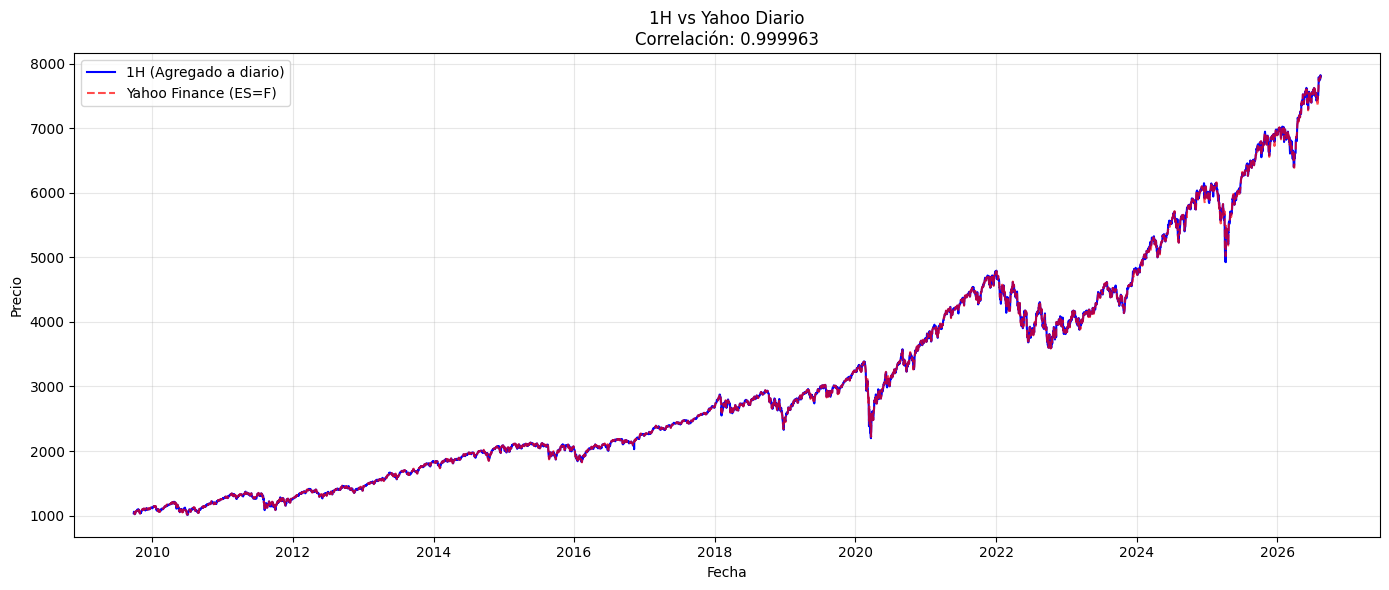

2026-08-15 21:51:19,012 - INFO - 🔄 Validación intradía directa para 1H (últimos 60 días)...
2026-08-15 21:51:19,018 - INFO - Descargando datos intradía 1H de Yahoo (ES=F)...
2026-08-15 21:51:19,479 - INFO - ✅ Reporte guardado en 'es_1h_validation_report.txt'.



📊 VALIDACIÓN INTRADÍA - 1H (últimos 60 días)
Correlación intradía: 0.960631
Error absoluto medio: 22.0580 puntos
Diferencia máxima:   143.5000 puntos
Estado: ⚠️ ADVERTENCIA


In [7]:
validation_1h = validate_against_yahoo(df_1h, "1H", VALIDATION_REPORT_1H, YAHOO_SYMBOL, INTRADAY_DAYS)

# 9. RESUMEN FINAL

In [10]:
print("\n" + "="*60)
print("📋 RESUMEN DE EXPORTACIÓN DE (15min, 1H, 4H, 1D)")
print("="*60)
print(f"Colección origen:       {COLLECTION_NAME}")
print(f"Datos base (15min):     {len(df_raw):,} registros")
print(f"Velas 1H generadas:     {len(df_1h):,}")
print(f"Velas 4H generadas:     {len(df_4h):,}")
print(f"Velas 1D generadas:     {len(df_daily):,}")
print(f"Archivo 15min:          {CSV_15MIN}")
print(f"Archivo 1H:             {CSV_1H}")
print(f"Archivo 4H:             {CSV_4H}")
print(f"Archivo 1D:             {CSV_1D}")
print(f"Validación 1H:          {'✅ PASÓ' if validation_1h else '⚠️ REVISAR'}")
print("="*60)

# Cerrar conexión
client.close()
logging.info("🔒 Conexión MongoDB cerrada.")

2026-08-15 22:39:18,083 - INFO - 🔒 Conexión MongoDB cerrada.



📋 RESUMEN DE EXPORTACIÓN DE (15min, 1H, 4H, 1D)
Colección origen:       es_15min
Datos base (15min):     397,203 registros
Velas 1H generadas:     101,021
Velas 4H generadas:     26,970
Velas 1D generadas:     5,252
Archivo 15min:          es_15min_full.csv
Archivo 1H:             es_1h_full.csv
Archivo 4H:             es_4h_full.csv
Archivo 1D:             es_1d.csv
Validación 1H:          ✅ PASÓ
